Evaluación 1

In [ ]:
import time
from pathlib import Path
import urllib.parse
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
MUESTRA_CLASE=6000
CATEGORIES = ["airplane","apple","fish","flower","umbrella","car","house","bicycle","guitar","shoe"]
EPOCHS = 10
LEARNING_RATE=0.001
BATCH_SIZE = 32

np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("Versión de TensorFlow:", tf.__version__)
print("Versión de Keras:", keras.__version__)



Versión de TensorFlow: 2.20.0
Versión de Keras: 3.13.2


In [ ]:
#url base para ir descargando por clase
base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

#lista con dibujos seleccionados de cada categoria
imgs = []

#lista con respuestas correctas
etiquetas = []


for etiqueta in range(len(CATEGORIES)):

    #recorre categoria en CATEGORIES
    categoria = CATEGORIES[etiqueta]

    #evidencia de la categoria cargada
    print("cargando:", categoria)

    #busca el archivo para descargarr
    ruta_archivo = keras.utils.get_file(fname=f"{categoria}.npy",
                                        origin=base_url + f"{categoria}.npy")

    #carga el archivo obtenido a partir de la ruta, r d solo lectura
    datos_categoria = np.load(ruta_archivo,
                              mmap_mode="r")


    #elige 6000 imgs random para cada categoria
    indices_elegidos = np.random.choice(len(datos_categoria),
                                        size=MUESTRA_CLASE,
                                        replace=False)

    #guardo los dibujos seleccionados en un array
    monos_seleccionados = np.asarray(datos_categoria[indices_elegidos])


    #respuestas correctas a las imagenes selecciionadas
    respuestas_correctas = np.full(MUESTRA_CLASE,
                                  etiqueta,
                                  dtype=np.int64)


    imgs.append(monos_seleccionados)
    etiquetas.append(respuestas_correctas)


x = np.concatenate(imgs, axis=0)
y = np.concatenate(etiquetas, axis=0)

#a formato 28x28
x = x.reshape(-1, 28, 28)

print("forma de x:", x.shape)
print("forma de y:", y.shape)

cargando: airplane
118872512/118872512 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
cargando: apple
113462128/113462128 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cargando: fish
105173680/105173680 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
cargando: flower
113537392/113537392 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cargando: umbrella
97281936/97281936 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cargando: car
143287056/143287056 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
cargando: house
106169360/106169360 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cargando: bicycle
99197248/99197248 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cargando: guitar
94433664/94433664 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
cargando: shoe
94261184/94261184 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
forma de x: (60000, 28, 28)
forma de y: (60000,)


In [ ]:
#valores min y max de los pixeles, deberian ser 0(negro) y 255(blanco)
print("valor min:", x.min())
print("valor max:", x.max())

valor min: 0
valor max: 255


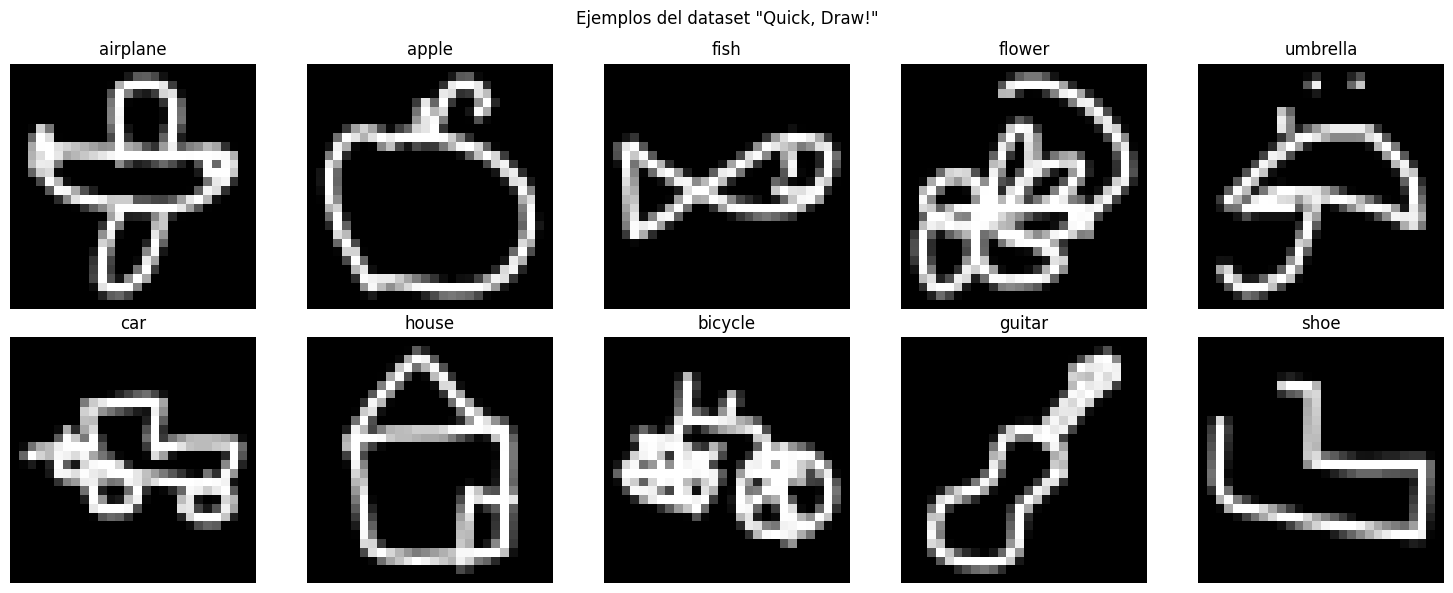

In [ ]:
#aqui se muentra una img de cada categoria

plt.figure(figsize=(15, 6))

for etiqueta in range(len(CATEGORIES)):
    indice = np.where(y == etiqueta)[0][0]

    plt.subplot(2, 5, etiqueta + 1)
    plt.imshow(x[indice], cmap="gray")
    plt.title(CATEGORIES[etiqueta])
    plt.axis("off")

plt.suptitle('Ejemplos del dataset "Quick, Draw!"')
plt.tight_layout()
plt.show()

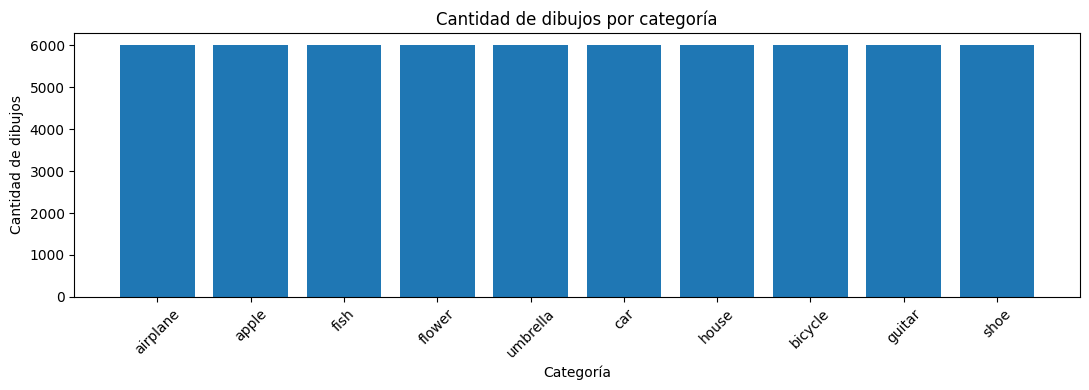

airplane 6000
apple 6000
fish 6000
flower 6000
umbrella 6000
car 6000
house 6000
bicycle 6000
guitar 6000
shoe 6000


In [ ]:
#aca se plotea la cantidad de imagenes por categoria, es el dataset completo y deberian ser 6000*10 categorias, es decir, 60000 img
valores, conteos = np.unique(
    y,
    return_counts=True
)

plt.figure(figsize=(11, 4))
plt.bar(CATEGORIES, conteos)
plt.title("Cantidad de dibujos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de dibujos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for etiqueta in range(len(CATEGORIES)):
    print(CATEGORIES[etiqueta], conteos[etiqueta])

In [ ]:
#division de img de dataset para training, validacion y prueba

"""train_test_split obtiene parametros test_size y train_size y wl conjunto se debe dividir en 3 asi que se agrego una variable de uso
temporal para dividir todo"""

x_train, x_temp, y_train, y_temp = train_test_split(x,
                                                    y,
                                                    test_size=0.30,
                                                    random_state=SEED,
                                                    stratify=y)



x_val, x_test, y_val, y_test = train_test_split(x_temp,
                                                y_temp,
                                                test_size=0.50,
                                                random_state=SEED,
                                                stratify=y_temp
)


print("entrenamiento:", x_train.shape, y_train.shape)
print("validacion:", x_val.shape, y_val.shape)
print("prueba:", x_test.shape, y_test.shape)

entrenamiento: (42000, 28, 28) (42000,)
validacion: (9000, 28, 28) (9000,)
prueba: (9000, 28, 28) (9000,)


In [ ]:
#normalizacion


x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [ ]:
#despues de la normalizacion, el dominio de x esta en [0,1]

print(x_train.min(), x_train.max())
print(x_val.min(), x_val.max())
print(x_test.min(), x_test.max())

0.0 1.0
0.0 1.0
0.0 1.0


In [ ]:
#creacion de modeloo, se crea una funcionn

def crear_model(hidden_neuronas):

  """capitas conectadas, img de 28x28, se transforma en un vector de 784, aprende en dense con relu (valores < 0 --> 0), softmax convierte
  resultados en probs (obviamente deben sumar 1 porque son probs)"""

  model = keras.Sequential([keras.Input(shape=(28,28)),
                            keras.layers.Flatten(),
                            keras.layers.Dense(hidden_neuronas,
                                              activation="relu"),
                            keras.layers.Dense(len(CATEGORIES),
                                               activation="softmax")])

  #se define el optimizador adam q ajusta el tamaño de los pesos
  optimizador = keras.optimizers.Adam(learning_rate=LEARNING_RATE)

  #como se actualizan los pesos (optm), como se calcula el error y precision
  model.compile(optimizer=optimizador,
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])

  return model

In [ ]:
#MODELOS CREAAR
modelo_128 = crear_model(128)
modelo_256 = crear_model(256)

modelo_128.summary()
modelo_256.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

Seq_arriba:


*   128 neuronas ocultas
*   784 en el vector (son pixeles)
*   dense_10 recibio 784 valores y produjo 128
*   dense_11 recibio 128 valores y produjo 10 (valor/categoria)
*   100.480 parametros = 784 entradas * 128 neuronas + 128 sesgos
*   1.290 parametros = 128 entradas * 10 categorías + 10 sesgos
*   Elemento de la lista

Seq_abajo:


*   256 neuronas ocultas
*   784 en el vector (son pixeles)
*   dense_10 recibio 784 valores y produjo 256
*   dense_11 recibio 256 valores y produjo 10 (valor/categoria)
*   200.960 parametros = 784 entradas * 256 neuronas + 256 sesgos
*   2.570 parametros = 256 entradas * 10 categorías + 10 sesgos
*   Elemento de la lista










ENTRENAMIENTO DE MODELOS

In [ ]:
#model 1 training

#inicio de proceso
inicio_128 = time.perf_counter()

"""se recibe imgs de train, realiza predicciones, compara con respuestas correctas, calcula error, actualiza pesos, repite para toda epoca
con validacion data se comprueba como responde el modelo ante imgs con las que no fue entrenado"""

history_128 = modelo_128.fit(x_train,
                            y_train,
                            validation_data=(x_val, y_val),
                            epochs=EPOCHS,
                            batch_size=BATCH_SIZE)

duracion_128 = time.perf_counter() - inicio_128

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8299 - loss: 0.5783 - val_accuracy: 0.8754 - val_loss: 0.4337
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8918 - loss: 0.3752 - val_accuracy: 0.8863 - val_loss: 0.3861
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9119 - loss: 0.3047 - val_accuracy: 0.8912 - val_loss: 0.3675
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9262 - loss: 0.2574 - val_accuracy: 0.8971 - val_loss: 0.3631
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9383 - loss: 0.2198 - val_accuracy: 0.8961 - val_loss: 0.3686
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9490 - loss: 0.1866 - val_accuracy: 0.8974 - val_loss: 0.3782
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9578 - loss: 0.1587 - val_accuracy: 0.8962 - val_loss: 0.3944
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9660 - loss: 0.1341 - 

In [ ]:
#model 2 training

#misma explcicacion del modelo anterior, pero ahora con este

inicio_256 = time.perf_counter()

history_256 = modelo_256.fit(x_train,
                            y_train,
                            validation_data=(x_val, y_val),
                            epochs=EPOCHS,
                            batch_size=BATCH_SIZE)

duracion_256 = time.perf_counter() - inicio_256

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8413 - loss: 0.5365 - val_accuracy: 0.8853 - val_loss: 0.3929
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9030 - loss: 0.3356 - val_accuracy: 0.8943 - val_loss: 0.3574
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9255 - loss: 0.2621 - val_accuracy: 0.8970 - val_loss: 0.3515
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9417 - loss: 0.2076 - val_accuracy: 0.8998 - val_loss: 0.3511
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9566 - loss: 0.1602 - val_accuracy: 0.8979 - val_loss: 0.3658
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9692 - loss: 0.1210 - val_accuracy: 0.8971 - val_loss: 0.3837
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9787 - loss: 0.0905 - val_accuracy: 0.8970 - val_loss: 0.4065
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9845 - loss: 0.0670 - 

In [ ]:
#duracion de entrenamiento mas ordenada

def duracion_min_seg(duracion):
  minutos = int(duracion // 60)
  segundos = duracion % 60
  return(f"{minutos} min {segundos:.2f} s")

print(f"Tiempo para modelo de 128 neuronas: {duracion_min_seg(duracion_128)}")
print(f"Tiempo para modelo de 256 neuronas: {duracion_min_seg(duracion_256)}")

Tiempo para modelo de 128 neuronas: 0 min 48.99 s
Tiempo para modelo de 256 neuronas: 1 min 1.53 s


In [ ]:
#graficasao de entrenamiento, funcion para aplicar a los dos modelos y no hacer todo 2 veces

def plotear_entrenamiento(history, nombre):

    datos = history.history
    epocas = range(1, len(datos["loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epocas, datos["accuracy"], label="Entrenamiento", marker="o")
    plt.plot(epocas, datos["val_accuracy"], label="Validación", marker="o")
    plt.title(f"Accuracy ({nombre}) por Época")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epocas, datos["loss"], label="Entrenamiento", marker="o")
    plt.plot(epocas, datos["val_loss"], label="Validación", marker="o")
    plt.title(f"Loss ({nombre}) por Época")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

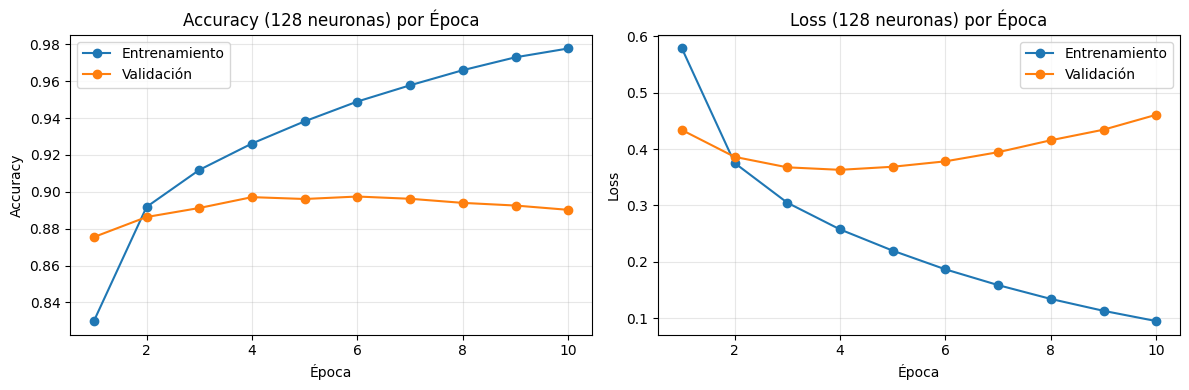

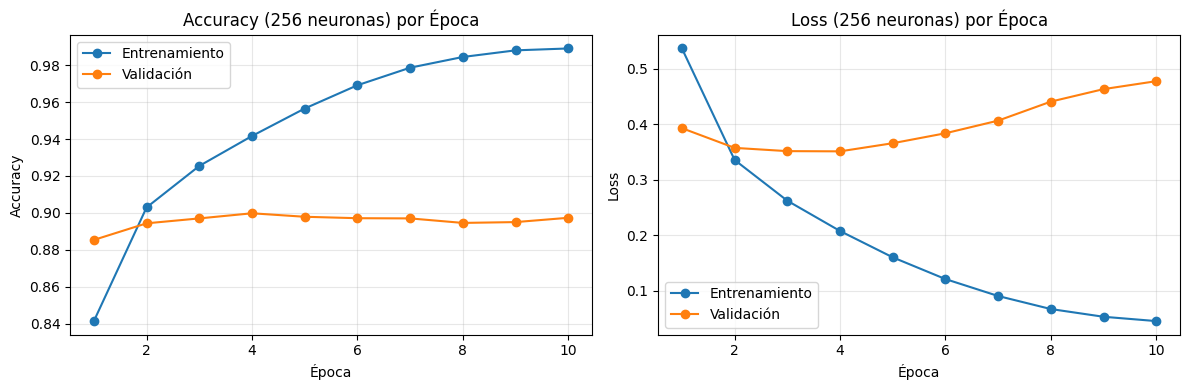

In [ ]:

plotear_entrenamiento(history_128, "128 neuronas")
plotear_entrenamiento(history_256, "256 neuronas")


In [ ]:
#evaluacion de modelos, compara xtest con sus respuestas correctas ytest, test_loss el error del modelo, y test_acc su accuracy(exactitudd)

test_loss_128, test_acc_128 = modelo_128.evaluate(
    x_test,
    y_test,
    verbose=0
)

test_loss_256, test_acc_256 = modelo_256.evaluate(
    x_test,
    y_test,
    verbose=0
)

In [ ]:
#que sucede realmente
print("128 neuronas:", test_loss_128, test_acc_128)
print("256 neuronas:", test_loss_256, test_acc_256)

128 neuronas: 0.46390360593795776 0.8953333497047424
256 neuronas: 0.512775182723999 0.8993333578109741


Se selecciona primero el modelo de 128 neuronas

In [ ]:
#modelo seleccionado para evaluar detalladamente : 128 neuronas

selected_model = modelo_128
selected_name = "128 neuronas"

In [ ]:

#predecir la categoria de cada imagen del conjunto test y escoge la clase mas probable
probabilidades_128 = modelo_128.predict(x_test,verbose=0)
predicted_clases_128 = np.argmax(probabilidades_128,axis=1)
name_128 = "128 neuronas"

probabilidades_256 = modelo_256.predict(x_test,verbose=0)
predicted_clases_256 = np.argmax(probabilidades_256,axis=1)
name_256 = "256 neuronas"

In [ ]:
#funcion que grafica las 20 primeras imagenes del conjunto del sataset

def plot_img_20(predicted_clases,probabilidades):
  plt.figure(figsize=(20, 8))

  for i in range(20):
      predicha = predicted_clases[i]
      real = y_test[i]
      confianza = probabilidades[i][predicha]
      color = "green" if predicha == real else "red"

      plt.subplot(4, 5, i + 1)
      plt.imshow(x_test[i], cmap="gray")
      plt.title(
          f"Real: {CATEGORIES[real]}\n"
          f"Pred: {CATEGORIES[predicha]}\n"
          f"Conf: {confianza:.1%}",
          color=color
      )
      plt.axis("off")

  plt.tight_layout()
  plt.show()

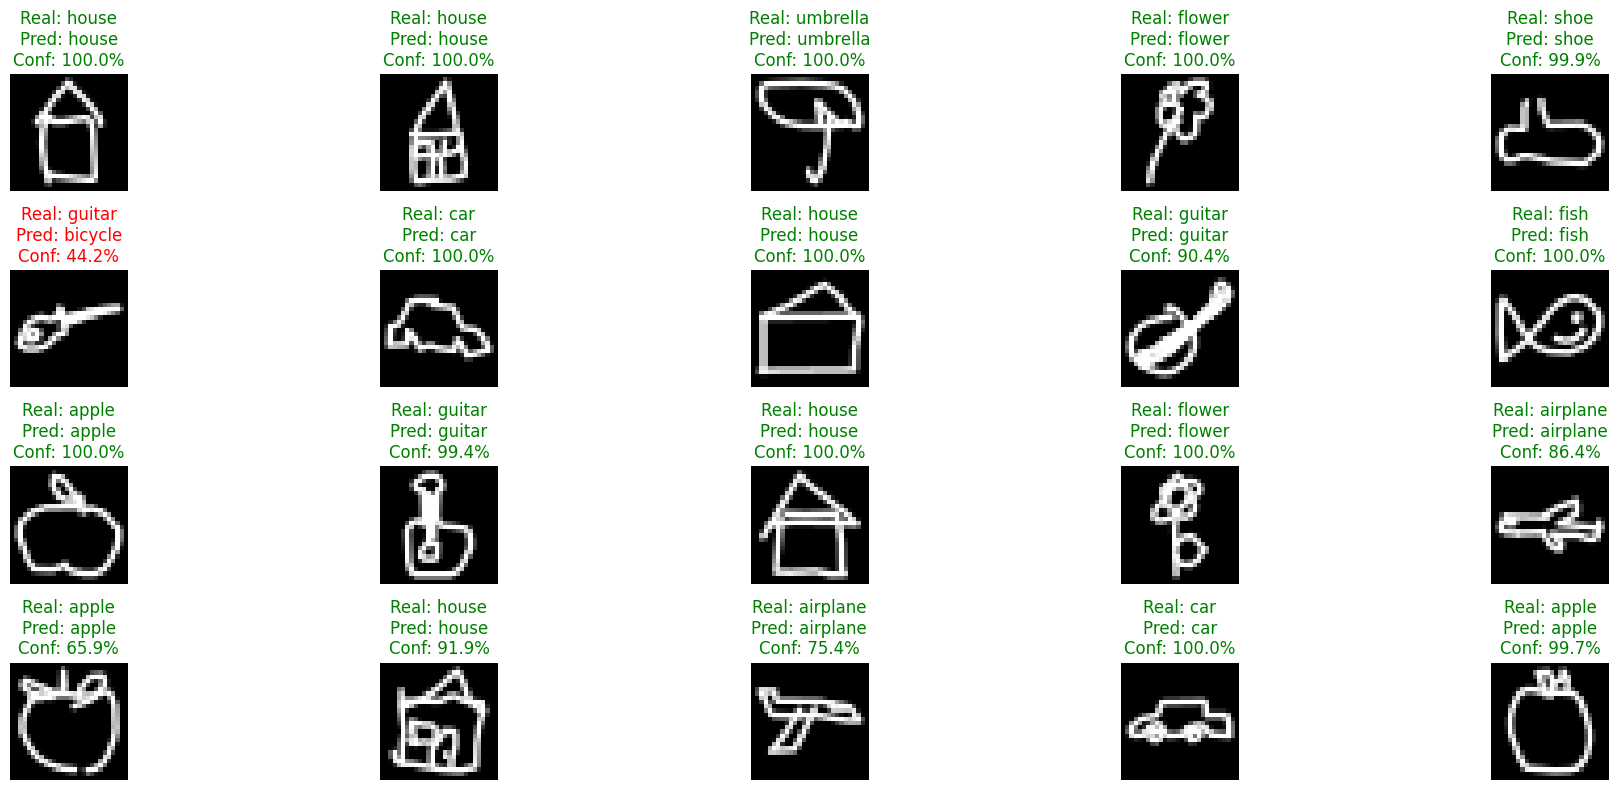

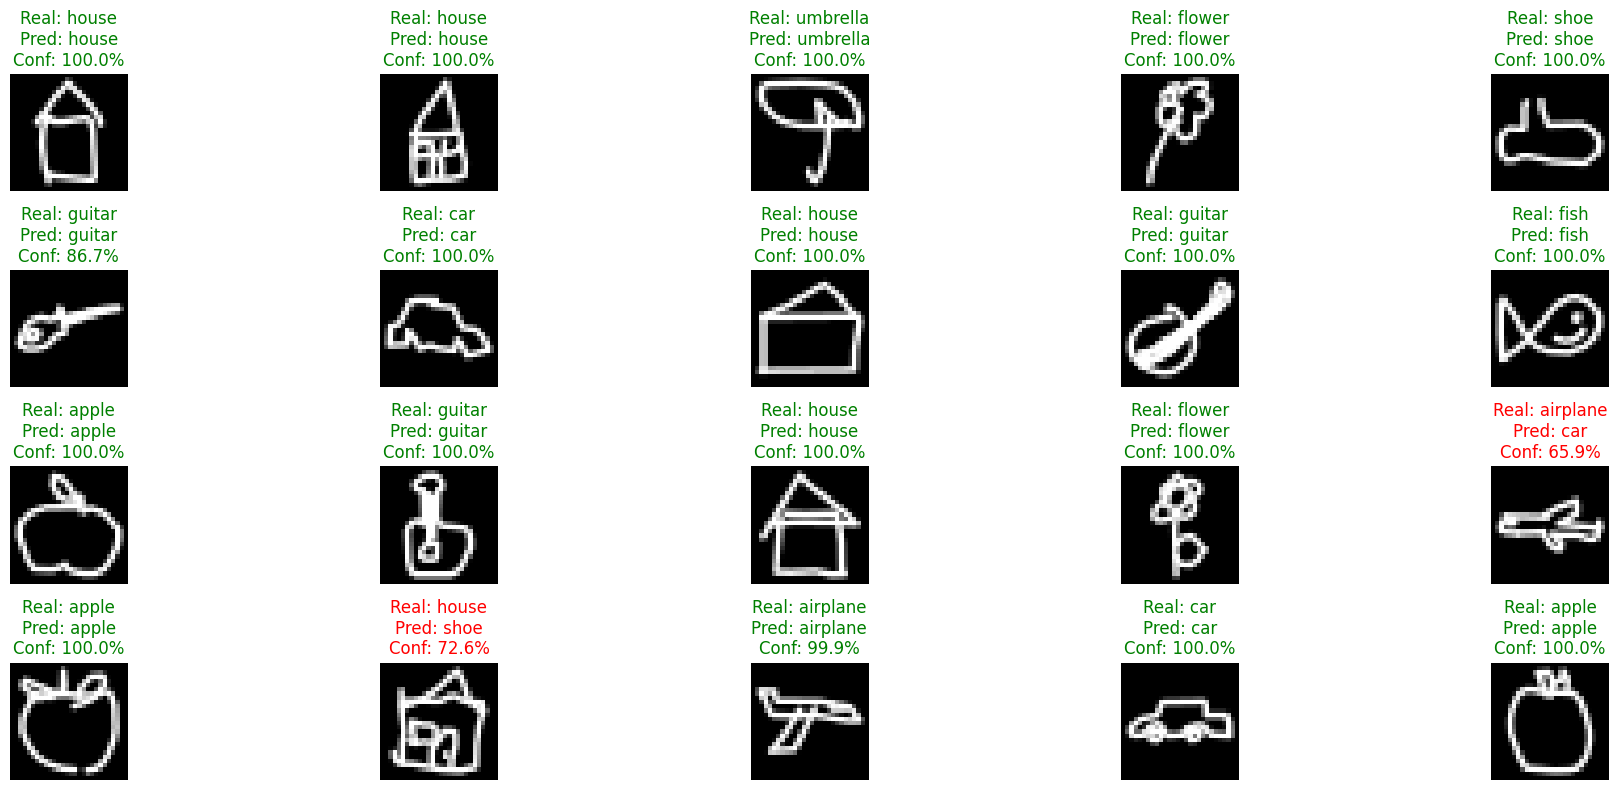

In [ ]:
#20 primeras imageness del conjunto de test del modelo-128

plot_img_20(predicted_clases_128,probabilidades_128)
print("")
plot_img_20(predicted_clases_256,probabilidades_256)

In [ ]:
#funcion matriz de confusion

def matriz_confusion(predicted_clases,neuronas):
  matriz = confusion_matrix(
      y_test,
      predicted_clases
  )

  disp = ConfusionMatrixDisplay(
      confusion_matrix=matriz,
      display_labels=CATEGORIES
  )


  fig, ax = plt.subplots(figsize=(10, 8))

  disp.plot(
      ax=ax,
      cmap="Blues",
      xticks_rotation=45
  )

  ax.set_title(f"Matriz de confusión ({neuronas} neuronas)")
  ax.set_xlabel("Categoría predicha")
  ax.set_ylabel("Categoría real")


  plt.tight_layout()
  plt.show()

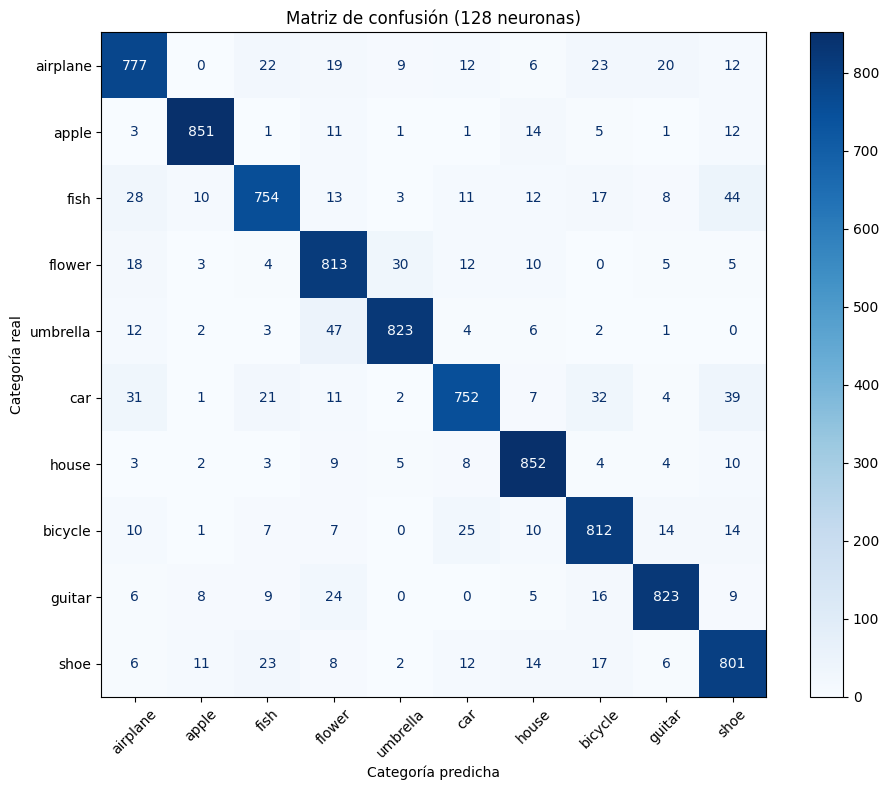

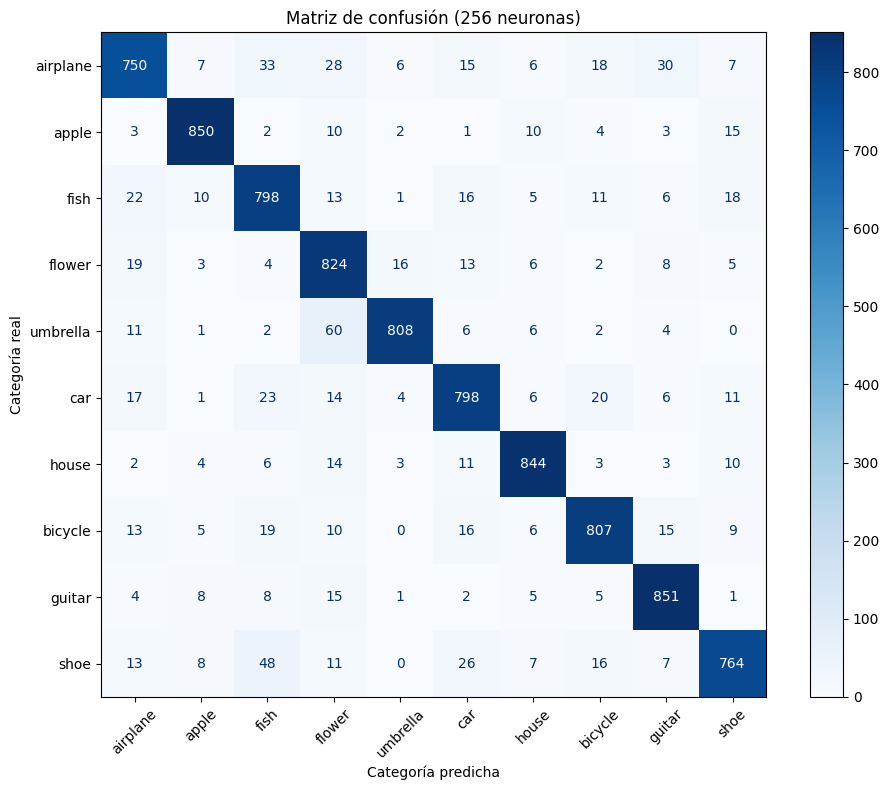

In [ ]:
matriz_confusion(predicted_clases_128,128)
print("\n\n")
matriz_confusion(predicted_clases_256,256)

In [ ]:
tabla_resultados = pd.DataFrame([
    {
        "Versión": "128 neuronas",
        "Épocas": EPOCHS,
        "Tasa de aprendizaje": LEARNING_RATE,
        "Accuracy entrenamiento": f"{history_128.history["accuracy"][-1]*100:.2f}%",
        "Loss entrenamiento": history_128.history["loss"][-1],
        "Accuracy validación": f"{history_128.history["val_accuracy"][-1]*100:.2f}%",
        "Loss validación": history_128.history["val_loss"][-1],
        "Accuracy prueba": f"{test_acc_128*100:.2f}%",
        "Loss prueba": test_loss_128,
        "Duración segundos": duracion_128
    },
    {
        "Versión": "256 neuronas",
        "Épocas": EPOCHS,
        "Tasa de aprendizaje": LEARNING_RATE,
        "Accuracy entrenamiento": f"{history_256.history["accuracy"][-1]*100:.2f}%",
        "Loss entrenamiento": history_256.history["loss"][-1],
        "Accuracy validación": f"{history_256.history["val_accuracy"][-1]*100:.2f}%",
        "Loss validación": history_256.history["val_loss"][-1],
        "Accuracy prueba": f"{test_acc_256*100:.2f}%",
        "Loss prueba": test_loss_256,
        "Duración segundos": duracion_256
    }
])

tabla_resultados.round(4)

,Versión,Épocas,Tasa de aprendizaje,Accuracy entrenamiento,Loss entrenamiento,Accuracy validación,Loss validación,Accuracy prueba,Loss prueba,Duración segundos
0,128 neuronas,10,0.001,97.78%,0.0949,89.02%,0.4608,89.53%,0.4639,48.9872
1,256 neuronas,10,0.001,98.92%,0.0453,89.73%,0.4775,89.93%,0.5128,61.5335


In [ ]:
#numero de predicciones correctas, incorrectas

total = len(y_test)

correctas_128 = np.sum(predicted_clases_128 == y_test)
incorrectas_128 = total - correctas_128

correctas_256 = np.sum(predicted_clases_256 == y_test)
incorrectas_256 = total - correctas_256

print("MODELO 128")
print(f"Predicciones correctas: {correctas_128}")
print(f"Predicciones incorrectas: {incorrectas_128}")
print("\n")
print("MODELO 256")
print(f"Predicciones correctas: {correctas_256}")
print(f"Predicciones incorrectas: {incorrectas_256}")

tablas_totales = pd.DataFrame([
    {
      "Modelo": "128 Neuronas",
      "Pred. correctas":correctas_128,
      "Pred. incorrectas": incorrectas_128
    },
    {
      "Modelo": "256 Neuronas",
      "Pred. correctas":correctas_256,
      "Pred. incorrectas":incorrectas_256
    }
])

tablas_totales


MODELO 128
Predicciones correctas: 8058
Predicciones incorrectas: 942


MODELO 256
Predicciones correctas: 8094
Predicciones incorrectas: 906


,Modelo,Pred. correctas,Pred. incorrectas
0,128 Neuronas,8058,942
1,256 Neuronas,8094,906


In [ ]:
#predicciones de mis dibujos
from PIL import Image, ImageOps

def predict_my_drawing(selected_model, neuronas):
  archivos = []
  DRAWINGS_DIR = Path("sample_drawings")

  for archivo in range(10):
      file_img = DRAWINGS_DIR / f"img_{archivo}.jpg"
      archivos.append(file_img)

  # Categoría real de cada imagen, desde img_0 hasta img_9
  categorias_reales = [
      "airplane",
      "house",
      "flower",
      "car",
      "shoe",
      "guitar",
      "umbrella",
      "bicycle",
      "fish",
      "apple"
  ]

  plt.figure(figsize=(15, 6))

  for posicion in range(len(archivos)):
      img = archivos[posicion]

      imagen = Image.open(img).convert("L").resize((28, 28))
      imagen = ImageOps.invert(imagen)
      imagen = np.array(imagen, dtype=np.float32) / 255.0

      probabilidades = selected_model.predict(
          imagen[None, ...],
          verbose=0
      )[0]

      prediccion = np.argmax(probabilidades)
      confianza = probabilidades[prediccion]

      categoria_predicha = CATEGORIES[prediccion]
      categoria_real = categorias_reales[posicion]

      # Verde si acierta y rojo si se equivoca
      color = (
          "green"
          if categoria_predicha == categoria_real
          else "red"
      )

      plt.subplot(2, 5, posicion + 1)
      plt.imshow(imagen, cmap="gray")

      plt.title(
          f"{img}\n"
          f"Real: {categoria_real}\n"
          f"Predicción: {categoria_predicha}\n"
          f"Confianza: {confianza:.1%}",
          color=color
      )

      plt.axis("off")

  plt.suptitle(f"Predicciones de mis dibujos ({neuronas} neuronas)", fontsize=16)
  plt.tight_layout()
  plt.show()



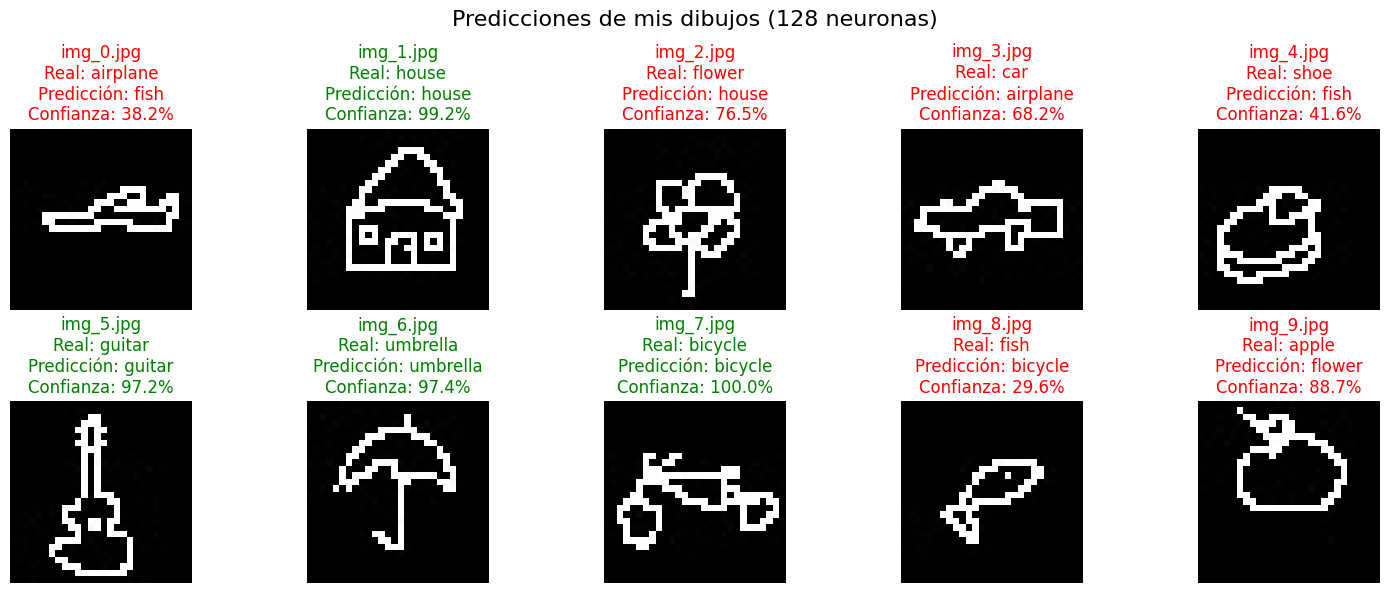

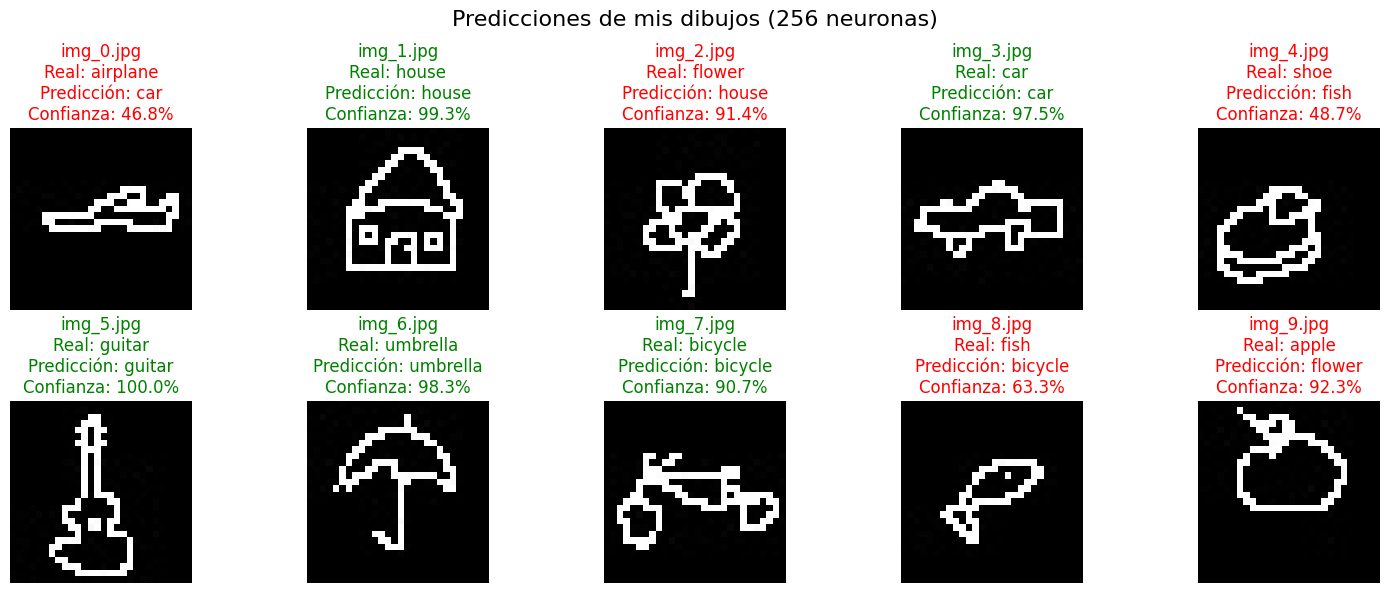

In [ ]:
predict_my_drawing(modelo_128,128)
print("\n\n")
predict_my_drawing(modelo_256,256)